# Prediction of Prosumers' Energy Behavior Project
# Exploratory analysis of the processed Enefit data

This notebook looks at the tables the training pipeline actually fits on:

- `data/processed/train_features.parquet` — one row per prediction unit, hour, and consumption/production flag, after the availability-aligned joins and the lag features.
- `data/processed/power.parquet` — the original `target` (power) kept aside so the model can be scored in the competition units.

The model does not fit power directly. It fits `capacity_factor = power / installed_capacity`, using the capacity that was known two days earlier, then multiplies the prediction back by that capacity.

A few rules of the processed table, so the plots are read the right way:

- Target lags start at 48 hours. Shorter lags are not in the file because those hours have not been revealed yet.
- `fw_*` is the forecast issued for that hour. `hw_*` is observed weather already shifted forward 48 hours, so it is the weather of two days ago.
- Electricity and gas prices are yesterday's prices. `electricity_price` is stored as an absolute value, so hours with a negative price look like a positive one.
- The first rows of each series are gone: the longest target lag is 336 hours, so the file starts on 17 September 2021 rather than 1 September.
- Rows from 1 April 2023 onward are the holdout. They are in this file, and they are kept out of fitting, tuning, and early stopping.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path('.').resolve()
FEATURES_PATH = ROOT / 'data' / 'processed' / 'train_features.parquet'
POWER_PATH = ROOT / 'data' / 'processed' / 'power.parquet'
COUNTY_PATH = ROOT / 'data' / 'raw' / 'county_id_to_name_map.json'

# Contract codes from the competition data dictionary.
PRODUCT_NAMES = {0: 'Combined', 1: 'Fixed', 2: 'General service', 3: 'Spot'}
HOLDOUT_START = pl.datetime(2023, 4, 1)

plt.rcParams.update({
    'figure.figsize': (11, 4),
    'axes.grid': True,
    'axes.axisbelow': True,
    'figure.facecolor': 'white',
})

features = pl.scan_parquet(FEATURES_PATH)
power = pl.scan_parquet(POWER_PATH)
county_names = {int(k): v.title() for k, v in json.loads(COUNTY_PATH.read_text(encoding='utf-8')).items()}
print(FEATURES_PATH.name, 'and', POWER_PATH.name)


train_features.parquet and power.parquet


## Descriptive statistics

One summary of every column in the processed table, pooled across consumption and production and across the whole date range, holdout included. `power` is the original target, joined from `power.parquet`. Means of `capacity_factor` mix the two series, so they are not the mean of either one on its own. `row_id` is only a key and is left out.


In [20]:
frame = features.join(power, on='row_id', how='left').collect()
described = frame.drop('row_id').describe()
stat_names = described['statistic'].to_list()
numeric_cols = [
    name for name, dtype in zip(described.columns, described.dtypes)
    if name != 'statistic' and dtype.is_numeric()
]

descriptive_stats = described.select(numeric_cols).transpose(
    include_header=True,
    header_name='column',
    column_names=stat_names,
)
n_unique = (
    frame.select([pl.col(name).n_unique().alias(name) for name in numeric_cols])
    .transpose(include_header=True, header_name='column', column_names=['n_unique'])
)
descriptive_stats = descriptive_stats.join(n_unique, on='column', how='left').select(
    'column', 'count', 'null_count', 'n_unique', 'mean', 'std', 'min', '25%', '50%', '75%', 'max',
)

pl.Config.set_tbl_rows(len(descriptive_stats))
pl.Config.set_fmt_float('mixed')
print(
    f"datetime from {frame['datetime'].min()} to {frame['datetime'].max()}, "
    f"{frame['datetime'].n_unique()} distinct hours"
)
descriptive_stats


datetime from 2021-09-17 00:00:00 to 2023-05-31 23:00:00, 14924 distinct hours


column,count,null_count,n_unique,mean,std,min,25%,50%,75%,max
str,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64
"""data_block_id""",1.954464e6,0.0,622,329.504654,177.854874,16.0,178.0,331.0,482.0,637.0
"""prediction_unit_id""",1.954464e6,0.0,69,32.986818,19.60464,0.0,16.0,33.0,50.0,68.0
"""is_consumption""",1.954464e6,0.0,2,0.5,null,0.0,null,null,null,1.0
"""county""",1.954464e6,0.0,16,7.282164,4.787591,0.0,3.0,7.0,11.0,15.0
"""is_business""",1.954464e6,0.0,2,0.536472,null,0.0,null,null,null,1.0
"""product_type""",1.954464e6,0.0,4,1.899488,1.084333,0.0,1.0,2.0,3.0,3.0
"""capacity_factor""",1.954464e6,0.0,1505972,0.182301,0.426276,0.0,0.000383,0.069204,0.23601,78.098833
"""installed_capacity""",1.954464e6,0.0,1937,1467.483759,2436.759026,6.0,324.2,651.7,1574.9,19314.31
"""electricity_price""",1.954464e6,0.0,10845,158.47805,122.637568,0.0,84.73,129.59,200.34,4000.0


### Coverage

Explore how many series and for how long.


In [2]:
overview = features.select(
    pl.len().alias('rows'),
    pl.col('datetime').min().alias('start'),
    pl.col('datetime').max().alias('end'),
    pl.col('data_block_id').n_unique().alias('blocks'),
    pl.col('prediction_unit_id').n_unique().alias('units'),
    pl.col('county').n_unique().alias('counties'),
    pl.col('product_type').n_unique().alias('product_types'),
    (pl.col('is_consumption').sum()).alias('consumption_rows'),
    ((~pl.col('is_consumption')).sum()).alias('production_rows'),
).collect()
overview


rows,start,end,blocks,units,counties,product_types,consumption_rows,production_rows
u32,datetime[μs],datetime[μs],u32,u32,u32,u32,u32,u32
1954464,2021-09-17 00:00:00,2023-05-31 23:00:00,622,69,16,4,977232,977232


### Missing values

Check whether the feature matrix still has holes.

In [3]:
null_counts = (
    features.select(pl.all().null_count())
    .unpivot(variable_name='column', value_name='nulls')
    .filter(pl.col('nulls') > 0)
    .sort('nulls', descending=True)
    .collect()
)
print(f'columns with nulls: {null_counts.height}')
null_counts


columns with nulls: 0


column,nulls
str,u32


In [4]:
# A prediction unit is one county x business flag x product type.
units = (
    features.group_by(['prediction_unit_id', 'county', 'is_business', 'product_type'])
    .agg(pl.len().alias('rows'), pl.col('datetime').min().alias('start'), pl.col('datetime').max().alias('end'))
    .with_columns(pl.col('county').replace_strict(county_names).alias('county_name'))
    .sort('prediction_unit_id')
    .collect()
)
print(f'{units.height} units, row count from {units["rows"].min()} to {units["rows"].max()}')
units.head(10)


69 units, row count from 1488 to 29848


prediction_unit_id,county,is_business,product_type,rows,start,end,county_name
i16,i8,bool,i8,u32,datetime[μs],datetime[μs],str
0,0,false,1,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
1,0,false,2,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
2,0,false,3,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
3,0,true,0,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
4,0,true,1,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
5,0,true,3,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Harjumaa"""
6,1,false,1,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Hiiumaa"""
7,1,false,3,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Hiiumaa"""
8,1,true,3,29848,2021-09-17 00:00:00,2023-05-31 23:00:00,"""Hiiumaa"""


### Outliers

Check whether the data still have outliers.

In [ ]:
# A 1.5-IQR fence on the raw values marks the long right tail of production,
# consumption and precipitation, on the order of a sixth of those rows. 
# The comparison here is how far the maximum sits past the 99th and 99.9th
# percentiles of the same segment. Consumption and production are kept apart.
TAIL_COLUMNS = [
    'capacity_factor',
    'power',
    'installed_capacity',
    'electricity_price',
    'gas_price',
    'fw_temperature',
    'hw_temperature',
    'fw_direct_solar_radiation',
    'fw_diffuse_solar_radiation',
    'fw_total_precipitation',
    'hw_total_precipitation',
    'hw_windspeed_10m',
]

scored = features.join(power.select('row_id', 'power'), on='row_id', how='left').with_columns(
    pl.when(pl.col('is_consumption')).then(pl.lit('consumption')).otherwise(pl.lit('production')).alias('segment')
)

tail = scored.group_by('segment').agg([
    item
    for column in TAIL_COLUMNS
    for item in (
        pl.col(column).min().alias(f'{column}__min'),
        pl.col(column).quantile(0.99).alias(f'{column}__p99'),
        pl.col(column).quantile(0.999).alias(f'{column}__p999'),
        pl.col(column).max().alias(f'{column}__max'),
    )
]).collect()

records = []
for segment in tail['segment'].to_list():
    row = tail.filter(pl.col('segment') == segment)
    for column in TAIL_COLUMNS:
        p99 = row[f'{column}__p99'][0]
        p999 = row[f'{column}__p999'][0]
        maximum = row[f'{column}__max'][0]
        records.append({
            'segment': segment,
            'column': column,
            'min': row[f'{column}__min'][0],
            'p99': p99,
            'p999': p999,
            'max': maximum,
            'max_over_p99': None if not p99 else maximum / p99,
            'max_over_p999': None if not p999 else maximum / p999,
        })

tail_summary = (
    pl.DataFrame(records)
    .sort(['segment', 'max_over_p99'], descending=[False, True])
)
pl.Config.set_tbl_rows(len(tail_summary))
tail_summary


segment,column,min,p99,p999,max,max_over_p99,max_over_p999
str,str,f64,f64,f64,f64,f64,f64
"""consumption""","""capacity_factor""",0.0,2.167024,3.933782,78.098833,36.039677,19.853372
"""consumption""","""fw_total_precipitation""",0.0,1.202393,2.559779,13.465881,11.199239,5.260564
"""consumption""","""electricity_price""",0.0,564.7,762.86,4000.0,7.083407,5.243426
"""consumption""","""hw_total_precipitation""",0.0,0.966667,2.02,6.2,6.413793,3.069307
"""consumption""","""power""",0.0,7198.433,12421.668,15480.274,2.150506,1.246232
"""consumption""","""fw_diffuse_solar_radiation""",0.0,201.175995,283.681641,358.222229,1.780641,1.262761
"""consumption""","""hw_windspeed_10m""",0.0,9.444445,11.736111,15.305555,1.620588,1.304142
"""consumption""","""installed_capacity""",6.0,14099.93,17975.58,19314.31,1.369816,1.074475
"""consumption""","""fw_temperature""",-26.417126,26.130884,29.604151,31.688623,1.212689,1.070411


consumption capacity-factor cut: 10.84 (5 x p99)
shape: (5, 2)
┌─────────────────────────────┬──────┐
│ rule                        ┆ rows │
│ ---                         ┆ ---  │
│ str                         ┆ u32  │
╞═════════════════════════════╪══════╡
│ production_cf_above_1       ┆ 66   │
│ consumption_cf_above_5x_p99 ┆ 96   │
│ non_positive_capacity       ┆ 0    │
│ negative_capacity_factor    ┆ 0    │
│ negative_electricity_price  ┆ 0    │
└─────────────────────────────┴──────┘
Production with capacity factor above 1
shape: (8, 7)
┌──────────────┬────────────┬──────────────┬──────────────┬──────────────┬──────────┬──────────────┐
│ datetime     ┆ segment    ┆ prediction_u ┆ installed_ca ┆ capacity_fac ┆ power    ┆ electricity_ │
│ ---          ┆ ---        ┆ nit_id       ┆ pacity       ┆ tor          ┆ ---      ┆ price        │
│ datetime[μs] ┆ str        ┆ ---          ┆ ---          ┆ ---          ┆ f64      ┆ ---          │
│              ┆            ┆ i16          ┆ f64  

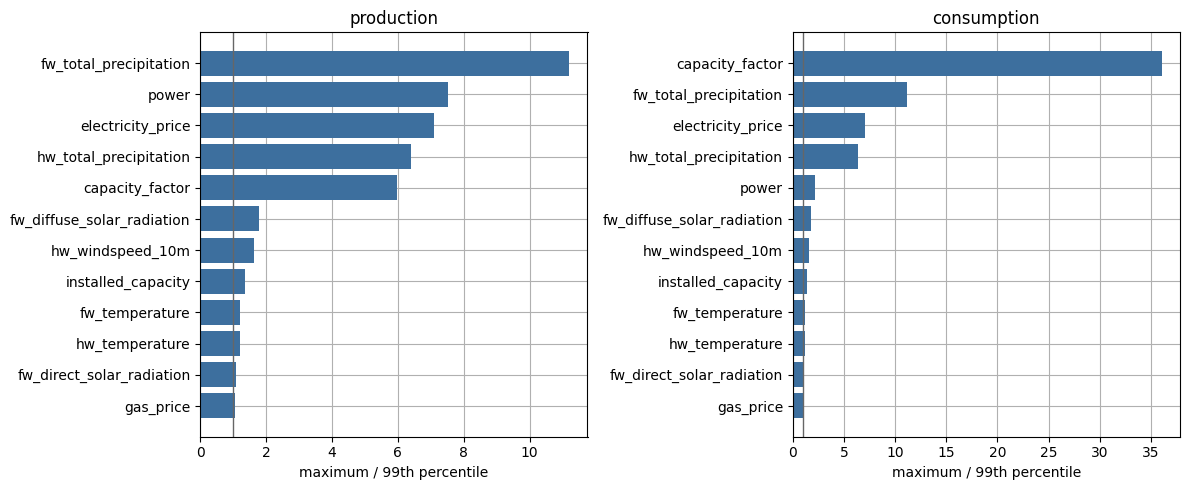

In [22]:
# Production above 1 generated more than the installed capacity in the denominator.
# Consumption above five times its own 99th percentile is the far tail of a ratio
# that is allowed to exceed 1, usually where the installed capacity is tiny.
consumption_p99 = tail_summary.filter(
    (pl.col('segment') == 'consumption') & (pl.col('column') == 'capacity_factor')
)['p99'][0]
consumption_cut = 5 * consumption_p99

bounds = scored.select(
    ((pl.col('segment') == 'production') & (pl.col('capacity_factor') > 1)).sum().alias('production_cf_above_1'),
    ((pl.col('segment') == 'consumption') & (pl.col('capacity_factor') > consumption_cut)).sum().alias('consumption_cf_above_5x_p99'),
    (pl.col('installed_capacity') <= 0).sum().alias('non_positive_capacity'),
    (pl.col('capacity_factor') < 0).sum().alias('negative_capacity_factor'),
    (pl.col('electricity_price') < 0).sum().alias('negative_electricity_price'),
).collect().unpivot(variable_name='rule', value_name='rows')
print(f'consumption capacity-factor cut: {consumption_cut:.2f} (5 x p99)')
print(bounds)

shown = ['datetime', 'segment', 'prediction_unit_id', 'installed_capacity', 'capacity_factor', 'power', 'electricity_price']
print('Production with capacity factor above 1')
print(
    scored.filter((pl.col('segment') == 'production') & (pl.col('capacity_factor') > 1))
    .select(shown)
    .sort('capacity_factor', descending=True)
    .head(8)
    .collect()
)
print('Consumption above the cut')
print(
    scored.filter((pl.col('segment') == 'consumption') & (pl.col('capacity_factor') > consumption_cut))
    .select(shown)
    .sort('capacity_factor', descending=True)
    .head(8)
    .collect()
)
print('Highest electricity prices, one row per hour')
print(
    scored.group_by('datetime')
    .agg(pl.col('electricity_price').first())
    .sort('electricity_price', descending=True)
    .head(5)
    .collect()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, segment in zip(axes, ('production', 'consumption')):
    part = tail_summary.filter(pl.col('segment') == segment).drop_nulls('max_over_p99').sort('max_over_p99')
    ax.barh(part['column'].to_list(), part['max_over_p99'].to_list(), color='#3d6f9e')
    ax.axvline(1, color='#666666', lw=1)
    ax.set_xlabel('maximum / 99th percentile')
    ax.set_title(segment)
fig.tight_layout()
plt.show()


### The target

Explore the target.
Target is capacity factor, that is:
 - for production: produced energy devided by installed capacity,
 - for consumption: consumpted energy devided by installed capacity.
 
Consumption and production share a schema and almost nothing else. Production is solar, so the capacity factor sits at zero overnight and rises with irradiance. Consumption divided by the same solar capacity is often above 1: the denominator is installed solar, not a load scale. Power, not the capacity factor, is what the competition scores.


In [5]:
joined = features.join(power, on='row_id', how='left')
target_summary = joined.group_by('is_consumption').agg(
    pl.len().alias('rows'),
    pl.col('power').null_count().alias('power_nulls'),
    pl.col('capacity_factor').median().alias('cf_p50'),
    pl.col('capacity_factor').quantile(0.99).alias('cf_p99'),
    pl.col('capacity_factor').max().alias('cf_max'),
    (pl.col('capacity_factor') > 1).mean().alias('share_cf_above_1'),
    pl.col('power').median().alias('power_p50'),
    pl.col('power').quantile(0.99).alias('power_p99'),
    pl.col('power').max().alias('power_max'),
    (pl.col('power') == 0).mean().alias('share_power_zero'),
    (pl.col('capacity_factor') * pl.col('installed_capacity') - pl.col('power')).abs().median().alias('median_abs_recon_error'),
).with_columns(
    pl.when(pl.col('is_consumption')).then(pl.lit('consumption')).otherwise(pl.lit('production')).alias('segment')
).sort('is_consumption')
target_summary.select(
    'segment', 'rows', 'power_nulls', 'cf_p50', 'cf_p99', 'cf_max', 'share_cf_above_1',
    'power_p50', 'power_p99', 'power_max', 'share_power_zero', 'median_abs_recon_error',
)


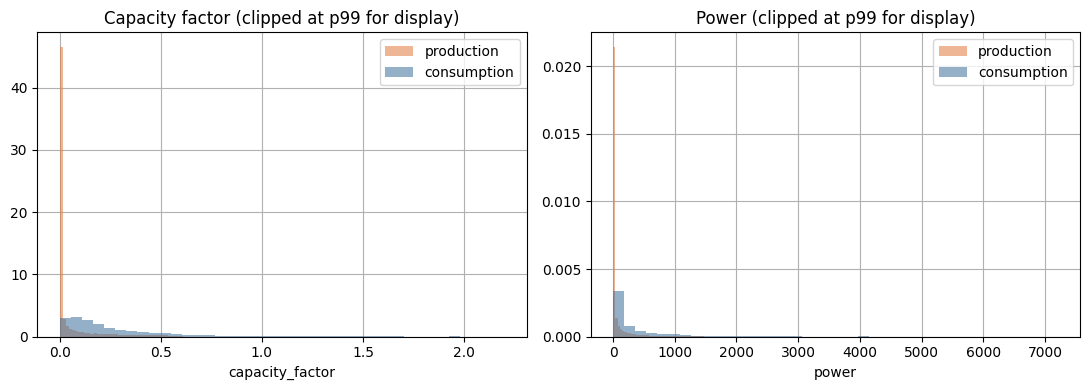

In [6]:
# Display is clipped at each segment's 99th percentile so the mass of the distribution is visible.
sample = (
    joined.select('is_consumption', 'capacity_factor', 'power')
    .collect()
    .sample(n=200_000, seed=0)
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title in (
    (axes[0], 'capacity_factor', 'Capacity factor'),
    (axes[1], 'power', 'Power'),
):
    for flag, label, color in ((False, 'production', '#e07a3d'), (True, 'consumption', '#3d6f9e')):
        values = sample.filter(pl.col('is_consumption') == flag)[column].to_numpy()
        cap = np.quantile(values, 0.99)
        ax.hist(values[values <= cap], bins=40, density=True, alpha=0.55, label=label, color=color)
    ax.set_title(title + ' (clipped at p99 for display)')
    ax.set_xlabel(column)
    ax.legend()
fig.tight_layout()
plt.show()


## Time of day, week, and year

Production should collapse outside daylight. Consumption should show a morning and evening peak, lower on weekends, and a winter lift.


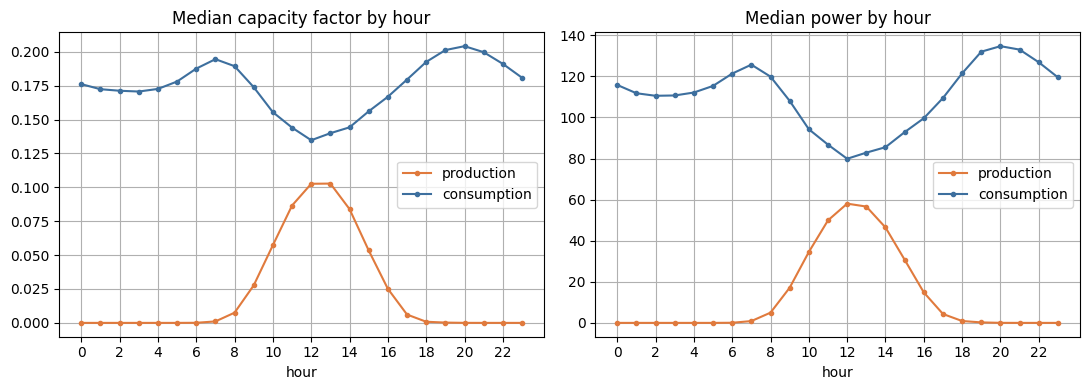

In [7]:
clock = features.with_columns(
    pl.col('datetime').dt.hour().alias('hour'),
    pl.col('datetime').dt.weekday().alias('weekday'),  # Monday = 1
    pl.col('datetime').dt.truncate('1mo').alias('month'),
    (pl.col('capacity_factor') * pl.col('installed_capacity')).alias('power_hat'),
)
hourly = (
    clock.group_by(['is_consumption', 'hour'])
    .agg(
        pl.col('capacity_factor').median().alias('cf_p50'),
        pl.col('power_hat').median().alias('power_p50'),
    )
    .sort(['is_consumption', 'hour'])
    .collect()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for flag, label, color in ((False, 'production', '#e07a3d'), (True, 'consumption', '#3d6f9e')):
    part = hourly.filter(pl.col('is_consumption') == flag).sort('hour')
    axes[0].plot(part['hour'], part['cf_p50'], marker='o', ms=3, label=label, color=color)
    axes[1].plot(part['hour'], part['power_p50'], marker='o', ms=3, label=label, color=color)
axes[0].set_title('Median capacity factor by hour')
axes[1].set_title('Median power by hour')
for ax in axes:
    ax.set_xlabel('hour')
    ax.set_xticks(range(0, 24, 2))
    ax.legend()
fig.tight_layout()
plt.show()


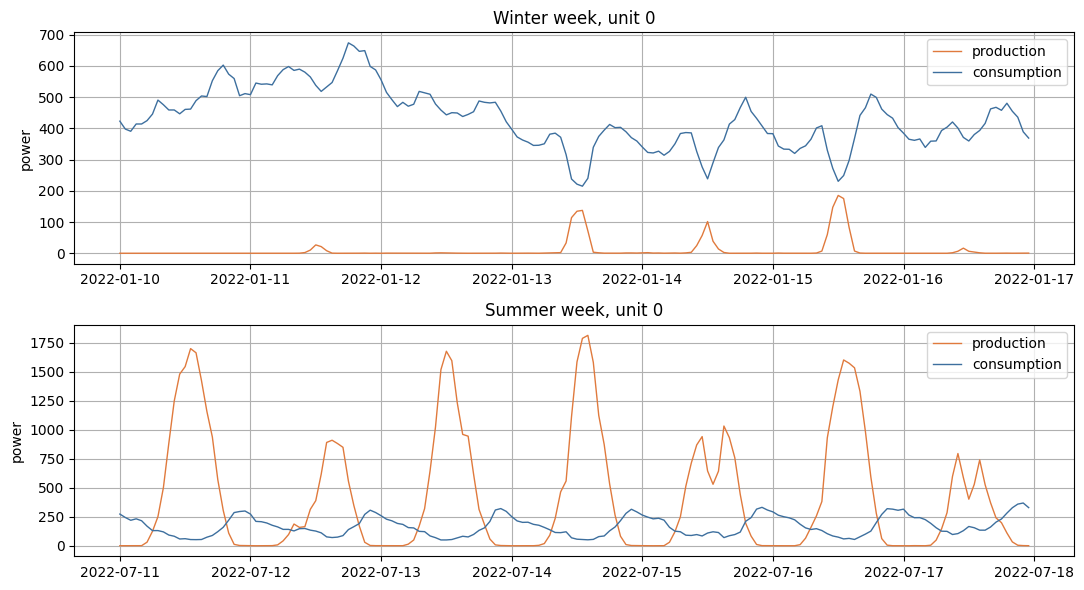

In [8]:
# One week of unit 0, winter and summer, in power units.
unit = (
    joined.filter(pl.col('prediction_unit_id') == 0)
    .select('datetime', 'is_consumption', 'power')
    .sort('datetime')
    .collect()
)
windows = [
    ('Winter week, unit 0', pl.datetime(2022, 1, 10), pl.datetime(2022, 1, 17)),
    ('Summer week, unit 0', pl.datetime(2022, 7, 11), pl.datetime(2022, 7, 18)),
]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=False)
for ax, (title, start, end) in zip(axes, windows):
    part = unit.filter((pl.col('datetime') >= start) & (pl.col('datetime') < end))
    for flag, label, color in ((False, 'production', '#e07a3d'), (True, 'consumption', '#3d6f9e')):
        series = part.filter(pl.col('is_consumption') == flag)
        ax.plot(series['datetime'].to_numpy(), series['power'].to_numpy(), label=label, color=color, lw=1)
    ax.set_title(title)
    ax.set_ylabel('power')
    ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


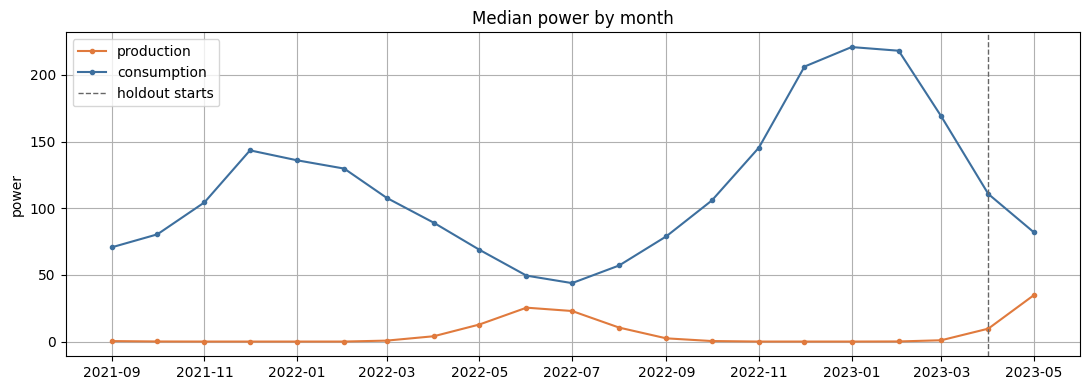

In [9]:
monthly = (
    clock.group_by(['month', 'is_consumption'])
    .agg(pl.col('power_hat').median().alias('power_p50'), pl.col('capacity_factor').median().alias('cf_p50'))
    .sort('month')
    .collect()
)
fig, ax = plt.subplots(figsize=(11, 4))
for flag, label, color in ((False, 'production', '#e07a3d'), (True, 'consumption', '#3d6f9e')):
    part = monthly.filter(pl.col('is_consumption') == flag)
    ax.plot(part['month'].to_numpy(), part['power_p50'].to_numpy(), marker='o', ms=3, label=label, color=color)
ax.axvline(np.datetime64('2023-04-01'), color='#666666', ls='--', lw=1, label='holdout starts')
ax.set_title('Median power by month')
ax.set_ylabel('power')
ax.legend()
fig.tight_layout()
plt.show()


Median power by holiday flag
shape: (4, 4)
┌────────────────┬────────────┬───────────┬────────┐
│ is_consumption ┆ is_holiday ┆ power_p50 ┆ rows   │
│ ---            ┆ ---        ┆ ---       ┆ ---    │
│ bool           ┆ bool       ┆ f64       ┆ u32    │
╞════════════════╪════════════╪═══════════╪════════╡
│ false          ┆ false      ┆ 0.39      ┆ 944232 │
│ false          ┆ true       ┆ 0.415     ┆ 33000  │
│ true           ┆ false      ┆ 111.4585  ┆ 944232 │
│ true           ┆ true       ┆ 106.327   ┆ 33000  │
└────────────────┴────────────┴───────────┴────────┘


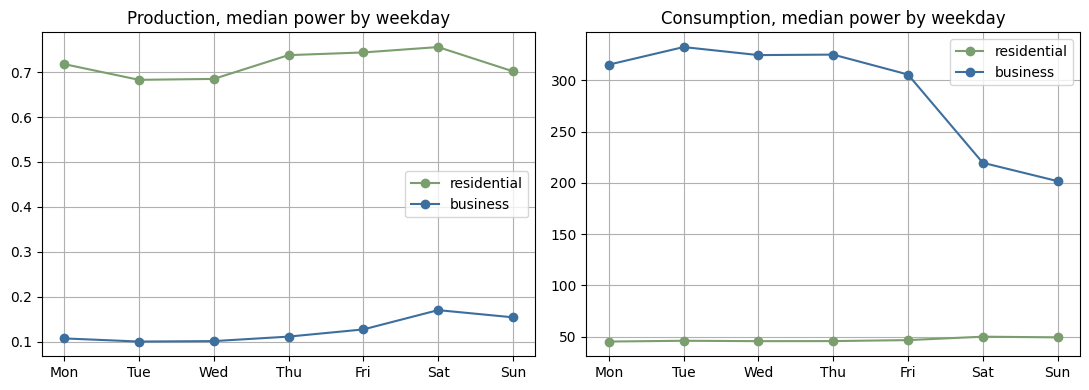

In [10]:
weekday = (
    clock.group_by(['is_consumption', 'is_business', 'weekday'])
    .agg(pl.col('power_hat').median().alias('power_p50'))
    .sort(['is_consumption', 'is_business', 'weekday'])
    .collect()
)
holiday = (
    clock.group_by(['is_consumption', 'is_holiday'])
    .agg(pl.col('power_hat').median().alias('power_p50'), pl.len().alias('rows'))
    .sort(['is_consumption', 'is_holiday'])
    .collect()
)
print('Median power by holiday flag')
print(holiday)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, flag, title in ((axes[0], False, 'Production'), (axes[1], True, 'Consumption')):
    for business, label, color in ((False, 'residential', '#7a9e6d'), (True, 'business', '#3d6f9e')):
        part = weekday.filter((pl.col('is_consumption') == flag) & (pl.col('is_business') == business))
        ax.plot(part['weekday'], part['power_p50'], marker='o', label=label, color=color)
    ax.set_title(title + ', median power by weekday')
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
    ax.legend()
fig.tight_layout()
plt.show()


## Who is in the panel

Installed solar capacity grows through the sample, and a handful of units carry most of the power. County 12 is the competition's unknown bucket.


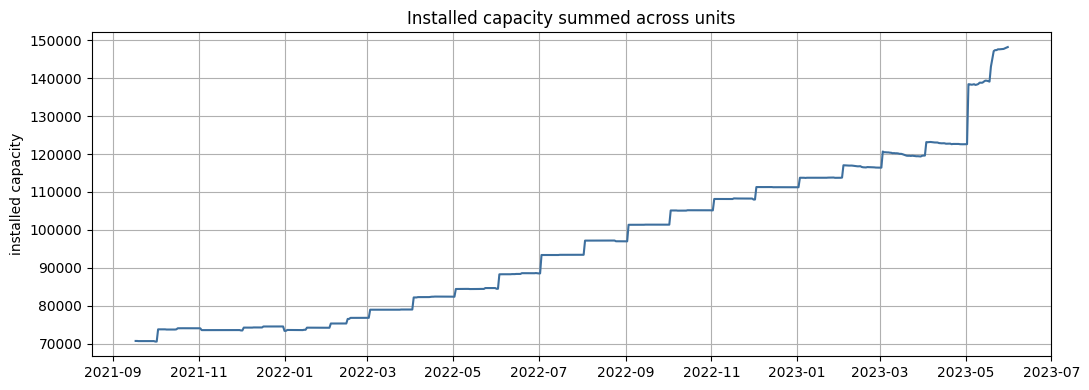

units on the first day 61, on the last day 65


In [11]:
# Capacity is a daily client attribute, so count each unit once per day.
daily_capacity = (
    features.filter(~pl.col('is_consumption'))
    .with_columns(pl.col('datetime').dt.date().alias('date'))
    .group_by(['date', 'prediction_unit_id'])
    .agg(pl.col('installed_capacity').first())
    .group_by('date')
    .agg(
        pl.col('installed_capacity').sum().alias('total_mw'),
        pl.col('prediction_unit_id').n_unique().alias('units'),
    )
    .sort('date')
    .collect()
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily_capacity['date'].to_numpy(), daily_capacity['total_mw'].to_numpy(), color='#3d6f9e')
ax.set_title('Installed capacity summed across units')
ax.set_ylabel('installed capacity')
fig.tight_layout()
plt.show()
print(
    f"units on the first day {daily_capacity['units'][0]}, "
    f"on the last day {daily_capacity['units'][-1]}"
)


In [12]:
# Mean power, not the median: production is zero for about half the hours, so the median
# collapses toward zero and hides which segments actually move the scored error.
segment_size = (
    clock.group_by(['county', 'is_business', 'product_type', 'is_consumption'])
    .agg(
        pl.col('power_hat').mean().alias('power_mean'),
        pl.col('power_hat').sum().alias('power_sum'),
        pl.col('installed_capacity').median().alias('capacity_p50'),
    )
    .with_columns(
        pl.col('county').replace_strict(county_names).alias('county_name'),
        pl.col('product_type').replace_strict(PRODUCT_NAMES).alias('product'),
        pl.when(pl.col('is_business')).then(pl.lit('business')).otherwise(pl.lit('residential')).alias('segment'),
        (pl.col('power_sum') / pl.col('power_sum').sum().over('is_consumption')).alias('share_of_segment_power'),
    )
    .sort('power_sum', descending=True)
    .collect()
)
shown = ['county_name', 'segment', 'product', 'power_mean', 'capacity_p50', 'share_of_segment_power']
print('Largest consumption segments by total power')
print(segment_size.filter(pl.col('is_consumption')).select(shown).head(8))
print('Largest production segments by total power')
print(segment_size.filter(~pl.col('is_consumption')).select(shown).head(8))


Largest consumption segments by total power
shape: (8, 6)
┌───────────────┬─────────────┬─────────┬─────────────┬──────────────┬────────────────────────┐
│ county_name   ┆ segment     ┆ product ┆ power_mean  ┆ capacity_p50 ┆ share_of_segment_power │
│ ---           ┆ ---         ┆ ---     ┆ ---         ┆ ---          ┆ ---                    │
│ str           ┆ str         ┆ str     ┆ f64         ┆ f64          ┆ f64                    │
╞═══════════════╪═════════════╪═════════╪═════════════╪══════════════╪════════════════════════╡
│ Harjumaa      ┆ business    ┆ Spot    ┆ 8045.95259  ┆ 15458.49     ┆ 0.263559               │
│ Tartumaa      ┆ business    ┆ Spot    ┆ 4583.807771 ┆ 5957.25      ┆ 0.15015                │
│ Viljandimaa   ┆ business    ┆ Spot    ┆ 1467.05479  ┆ 3921.3       ┆ 0.048056               │
│ Harjumaa      ┆ residential ┆ Spot    ┆ 1339.954135 ┆ 9303.56      ┆ 0.043892               │
│ Saaremaa      ┆ business    ┆ Spot    ┆ 1066.972494 ┆ 2075.4       ┆ 0.03495

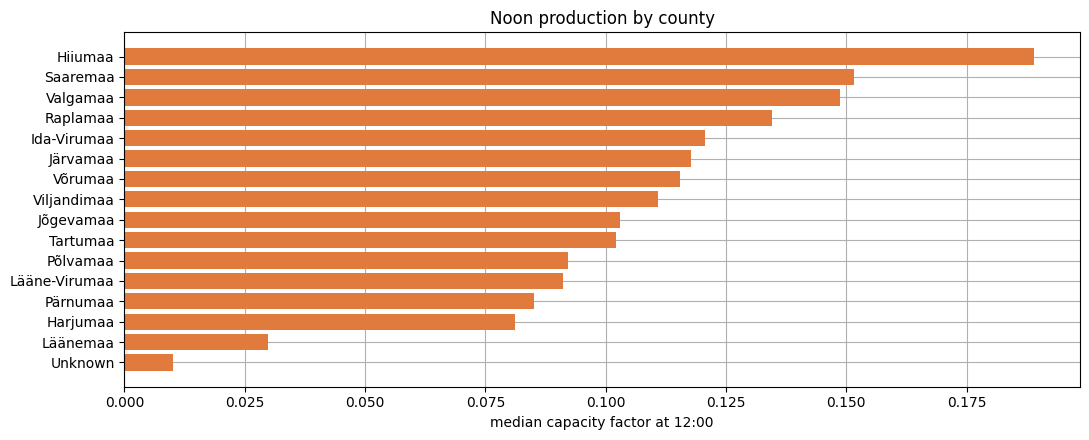

In [13]:
# Noon production capacity factor, so the comparison is not washed out by the night zeros.
noon = (
    clock.filter((~pl.col('is_consumption')) & (pl.col('hour') == 12))
    .group_by('county')
    .agg(pl.col('capacity_factor').median().alias('cf_p50'), pl.col('power_hat').median().alias('power_p50'))
    .with_columns(pl.col('county').replace_strict(county_names).alias('county_name'))
    .sort('cf_p50', descending=True)
    .collect()
)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(noon['county_name'].to_list()[::-1], noon['cf_p50'].to_list()[::-1], color='#e07a3d')
ax.set_xlabel('median capacity factor at 12:00')
ax.set_title('Noon production by county')
fig.tight_layout()
plt.show()


## Weather and prices

Forecast direct solar radiation is the covariate that should track production. Observed temperature, already delayed 48 hours, is a weak stand-in for the heating-driven part of consumption. Prices move on a different clock from either series.


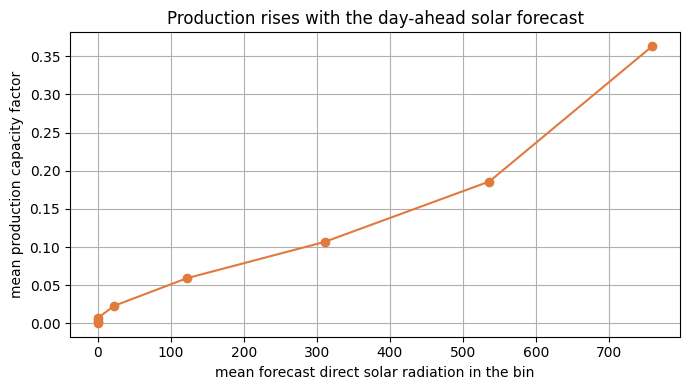

In [14]:
production = clock.filter(~pl.col('is_consumption'))
bins = (
    production.with_columns(
        pl.col('fw_direct_solar_radiation').qcut(12, labels=[str(i) for i in range(12)], allow_duplicates=True).alias('solar_bin')
    )
    .group_by('solar_bin')
    .agg(
        pl.col('fw_direct_solar_radiation').mean().alias('solar'),
        pl.col('capacity_factor').mean().alias('cf'),
        pl.len().alias('rows'),
    )
    .sort('solar')
    .collect()
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bins['solar'], bins['cf'], marker='o', color='#e07a3d')
ax.set_xlabel('mean forecast direct solar radiation in the bin')
ax.set_ylabel('mean production capacity factor')
ax.set_title('Production rises with the day-ahead solar forecast')
fig.tight_layout()
plt.show()


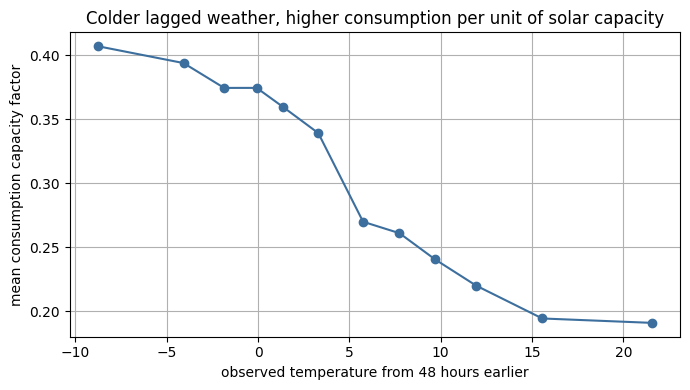

In [15]:
temp_bins = (
    clock.filter(pl.col('is_consumption'))
    .with_columns(pl.col('hw_temperature').qcut(12, allow_duplicates=True).alias('temp_bin'))
    .group_by('temp_bin')
    .agg(
        pl.col('hw_temperature').mean().alias('temperature'),
        pl.col('capacity_factor').mean().alias('cf'),
    )
    .sort('temperature')
    .collect()
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(temp_bins['temperature'], temp_bins['cf'], marker='o', color='#3d6f9e')
ax.set_xlabel('observed temperature from 48 hours earlier')
ax.set_ylabel('mean consumption capacity factor')
ax.set_title('Colder lagged weather, higher consumption per unit of solar capacity')
fig.tight_layout()
plt.show()


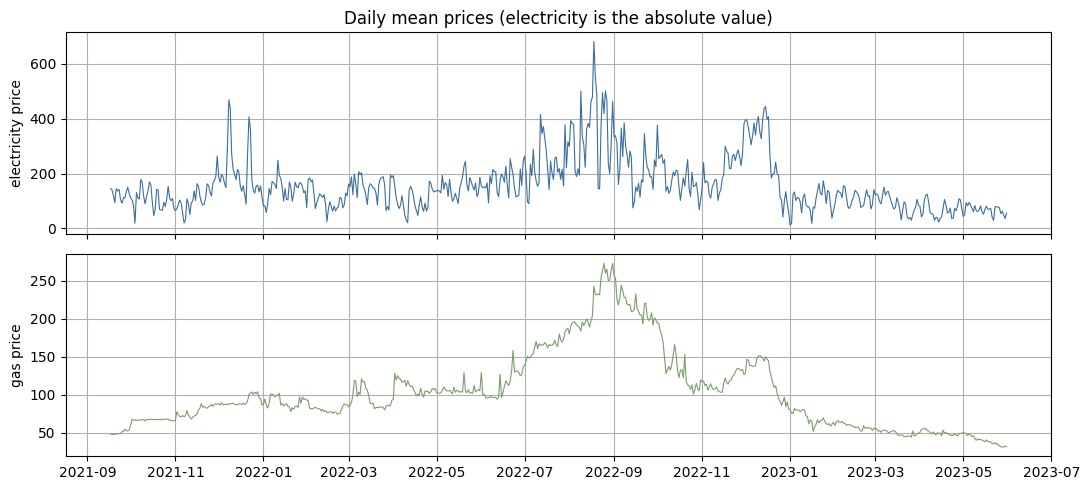

electricity min 11.47, max 682.05; share of hours at 0: 0.000


In [16]:
prices = (
    features.with_columns(pl.col('datetime').dt.truncate('1d').alias('day'))
    .group_by('day')
    .agg(
        pl.col('electricity_price').mean().alias('electricity'),
        pl.col('gas_price').mean().alias('gas'),
    )
    .sort('day')
    .collect()
)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(prices['day'].to_numpy(), prices['electricity'].to_numpy(), color='#3d6f9e', lw=0.8)
axes[0].set_ylabel('electricity price')
axes[0].set_title('Daily mean prices (electricity is the absolute value)')
axes[1].plot(prices['day'].to_numpy(), prices['gas'].to_numpy(), color='#7a9e6d', lw=0.8)
axes[1].set_ylabel('gas price')
fig.tight_layout()
plt.show()
print(
    f"electricity min {prices['electricity'].min():.2f}, max {prices['electricity'].max():.2f}; "
    f"share of hours at 0: "
    f"{features.select((pl.col('electricity_price') == 0).mean()).collect().item():.3f}"
)


## What the lags already capture

These correlations are on the capacity factor, inside each segment. They are a ceiling check for a dumb baseline, not a feature ranking: solar and the lags move together, so the correlations are not additive.


In [17]:
candidates = [
    'capacity_factor_lag_48',
    'capacity_factor_lag_168',
    'capacity_factor_lag_336',
    'capacity_factor_same_hour_mean_7d',
    'capacity_factor_same_hour_std_7d',
    'fw_direct_solar_radiation',
    'fw_diffuse_solar_radiation',
    'fw_cloudcover_total',
    'fw_temperature',
    'hw_temperature',
    'hw_direct_solar_radiation',
    'electricity_price',
    'gas_price',
    'installed_capacity',
    'hour_sin',
    'hour_cos',
]
rows = []
for flag, segment in ((False, 'production'), (True, 'consumption')):
    corrs = features.filter(pl.col('is_consumption') == flag).select(
        [pl.corr('capacity_factor', name).alias(name) for name in candidates]
    ).collect()
    for name in candidates:
        rows.append({'segment': segment, 'feature': name, 'corr': corrs[name][0]})
correlations = pl.DataFrame(rows).sort(['segment', 'corr'], descending=[False, True])
correlations


segment,feature,corr
str,str,f64
"""consumption""","""capacity_factor_same_hour_mean…",0.648048
"""consumption""","""capacity_factor_lag_168""",0.541476
"""consumption""","""capacity_factor_lag_48""",0.517631
"""consumption""","""capacity_factor_lag_336""",0.508501
"""consumption""","""capacity_factor_same_hour_std_…",0.233259
…,…,…
"""production""","""electricity_price""",0.004159
"""production""","""installed_capacity""",-0.004311
"""production""","""hour_sin""",-0.091111


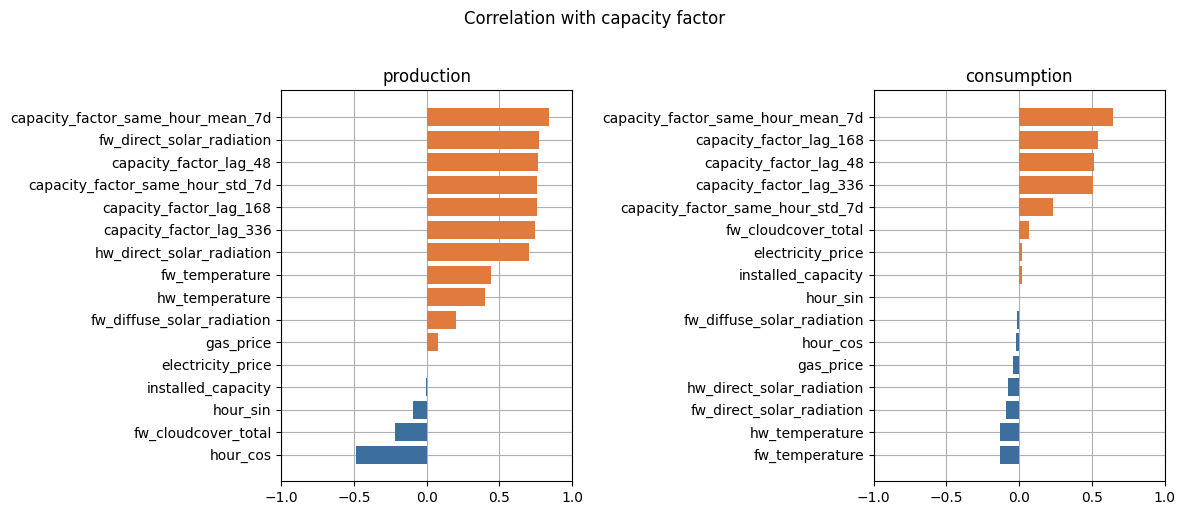

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, segment in zip(axes, ('production', 'consumption')):
    part = correlations.filter(pl.col('segment') == segment).sort('corr')
    colors = ['#e07a3d' if c > 0 else '#3d6f9e' for c in part['corr'].to_list()]
    ax.barh(part['feature'].to_list(), part['corr'].to_list(), color=colors)
    ax.set_xlim(-1, 1)
    ax.set_title(segment)
fig.suptitle('Correlation with capacity factor', y=1.02)
fig.tight_layout()
plt.show()


## Holdout versus the months used for fitting

April and May 2023 stay in the parquet and stay out of training. The comparison below is whether that window is a different season, not a score.


In [19]:
split = (
    clock.with_columns((pl.col('datetime') >= HOLDOUT_START).alias('holdout'))
    .group_by(['holdout', 'is_consumption'])
    .agg(
        pl.len().alias('rows'),
        pl.col('datetime').min().alias('start'),
        pl.col('datetime').max().alias('end'),
        pl.col('power_hat').median().alias('power_p50'),
        pl.col('capacity_factor').median().alias('cf_p50'),
        pl.col('fw_direct_solar_radiation').median().alias('solar_p50'),
        pl.col('hw_temperature').median().alias('temp_p50'),
        pl.col('installed_capacity').median().alias('capacity_p50'),
    )
    .with_columns(
        pl.when(pl.col('is_consumption')).then(pl.lit('consumption')).otherwise(pl.lit('production')).alias('segment'),
        pl.when(pl.col('holdout')).then(pl.lit('holdout')).otherwise(pl.lit('fit window')).alias('window'),
    )
    .sort(['segment', 'holdout'])
)
split.select(
    'window', 'segment', 'rows', 'start', 'end',
    'power_p50', 'cf_p50', 'solar_p50', 'temp_p50', 'capacity_p50',
).collect()


window,segment,rows,start,end,power_p50,cf_p50,solar_p50,temp_p50,capacity_p50
str,str,u32,datetime[μs],datetime[μs],f64,f64,f32,f32,f64
"""fit window""","""consumption""",882240,2021-09-17 00:00:00,2023-03-31 23:00:00,112.779,0.182538,0.0,3.72,637.4
"""holdout""","""consumption""",94992,2023-04-01 00:00:00,2023-05-31 23:00:00,95.9605,0.109958,156.208893,8.475,1040.6
"""fit window""","""production""",882240,2021-09-17 00:00:00,2023-03-31 23:00:00,0.227,0.000226,0.0,3.72,637.4
"""holdout""","""production""",94992,2023-04-01 00:00:00,2023-05-31 23:00:00,18.9235,0.022531,156.208893,8.475,1040.6


## Reading for the model

Production is a daylight series. The day-ahead solar forecast and the same-hour history (48 hours back, and the 7-day same-hour mean) already line up with it. Consumption is smoother across the day, larger in winter and on business days, and only loosely tied to the 48-hour-old temperature. Because consumption is scaled by solar capacity, its capacity factor is not bounded by 1, and the biggest counties dominate absolute error even when their capacity factor looks ordinary.

Two things in this file will mislead a later comparison if they are forgotten: electricity prices have had the sign removed, and the holdout is the bright, high-capacity end of the sample rather than a random slice of it.
